## Eni Mozambique Data
---
 This notebook is intended to focus only on selective stations in the northern Mozambique Channel offshore area that [WWS](https://www.weatherwatersand.com/) is interested in within their project with Eni. The goal is to provide an informative plot about storm events and the data that is available for that period in the stations.
 
 `version 1.0, May, 20, 2026, auth:moeindst`
 
 ---

In [ ]:
### importing libraries and packages
from pathlib import Path
import re
from io import StringIO

import xarray as xr
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

* I want to indicate the nature of the information available for each station during the storm events. I find it more iinformative to assign different colors to bars. For this I need to create a dictionary of categories.

In [ ]:
category_patterns = {
    "meteo": [
        "wind_speed",
        "wind_direction",
        "air_temperature",
        "air_pressure",
        "relative_humidity",
    ],
    "wave": [
        "hs",
        "hm0",
        "tp",
        "tm",
        "wave_direction",
        "peak_period",
        "mean_period",
    ],
    "current": [
        "current_speed",
        "current_direction",
    ],
    "water_property": [
        "temperature",
        "salinity",
        "turbidity",
    ],
}

In [ ]:
def classify_variable(varname, category_patterns):
    name = varname.lower()

    matches = []
    for category, patterns in category_patterns.items():
        for pattern in patterns:
            if pattern in name:
                matches.append(category)
                break

    return matches

def valid_intervals_from_boolean_time(time, valid, gap_tolerance="0H"):
    df = pd.DataFrame({
        "time": pd.to_datetime(time),
        "valid": np.asarray(valid, dtype=bool),
    }).sort_values("time")

    valid_times = df.loc[df["valid"], "time"]

    if valid_times.empty:
        return []

    gap_tolerance = pd.Timedelta(gap_tolerance)

    # estimating native sampling interval from all timestamps, not only valid ones!
    time_diffs = df["time"].diff().dropna()
    native_dt = time_diffs.median()

    max_allowed_gap = native_dt + gap_tolerance

    intervals = []
    start = valid_times.iloc[0]
    previous = valid_times.iloc[0]

    for current in valid_times.iloc[1:]:
        gap = current - previous

        if gap > max_allowed_gap:
            intervals.append((start, previous))
            start = current

        previous = current

    intervals.append((start, previous))

    return intervals

In [ ]:
nc_folder = Path("/home/moein/Data/eni_mozambique_wws/data/netcdf/")
stations_of_interest = ["W1", "C1", "C11A", "C12A", "C2", "C9B", "C4", "C6"]

In [ ]:
inventory_rows = []

for nc_file in sorted(nc_folder.glob("*.nc")):
    ds = xr.open_dataset(nc_file)

    station_name = ds.attrs.get("location")

    if station_name not in stations_of_interest:
        ds.close()
        continue

    for var in ds.data_vars:
        categories = classify_variable(var, category_patterns)

        inventory_rows.append({
            "file": nc_file.name,
            "station_name": station_name,
            "variable": var,
            "categories": ", ".join(categories) if categories else "",
        })

    ds.close()

inventory_df = pd.DataFrame(inventory_rows)
inventory_df

In [ ]:
%%time

coverage_rows = []

gap_tolerance = "3H"

for nc_file in sorted(nc_folder.glob("*.nc")):
    ds = xr.open_dataset(nc_file)

    station_name = ds.attrs.get("location")

    if station_name not in stations_of_interest:
        ds.close()
        continue

    for category in category_patterns:
        category_vars = []

        for var in ds.data_vars:
            categories = classify_variable(var, category_patterns)
            if category in categories and "time" in ds[var].dims:
                category_vars.append(var)

        if not category_vars:
            continue

        valid = ds[category_vars].to_array().notnull().any(dim="variable")

        # If variables have extra dimensions, reduce them too
        other_dims = [d for d in valid.dims if d != "time"]
        if other_dims:
            valid = valid.any(dim=other_dims)

        intervals = valid_intervals_from_boolean_time(
            time=ds["time"].values,
            valid=valid.values,
            gap_tolerance=gap_tolerance,
        )

        for start_time, end_time in intervals:
            coverage_rows.append({
                "file": nc_file.name,
                "station_name": station_name,
                "category": category,
                "start_time": start_time,
                "end_time": end_time,
                "variables": ", ".join(category_vars),
            })

    ds.close()

coverage_valid_df = pd.DataFrame(coverage_rows)
coverage_valid_df

In [ ]:
import matplotlib.dates as mdates

In [ ]:
ds_storm = xr.open_dataset(os.path.join(nc_folder,'Final_W1_Wavescan_Wave.nc'))

In [ ]:
threshold = 2.4
gap_tolerance = pd.Timedelta("3H")

hs = ds_storm["significant_wave_height"]

df_storm = pd.DataFrame({
    "time": pd.to_datetime(ds_storm["time"].values),
    "Hs": hs.values
})

### keeping only instances that go above threshold
df_storm = df_storm[df_storm["Hs"] > threshold].copy()

### time gap between consecutive instances
df_storm["dt"] = df_storm["time"].diff()

### new storm event if gap > tolerance
### This important for treating the NaNs. Otherwise, if NaN
### is encountered, the period will be divided since NaN will
### be deciphered as > 2.4
df_storm["event_id"] = (
    df_storm["dt"] > gap_tolerance
).cumsum() + 1

storm_periods1 = (
    df_storm.groupby("event_id").agg(
        start_time=("time", "min"),
        end_time=("time", "max"),
        Hs_max=("Hs", "max"),
        n_points=("Hs", "count")
                                    ).reset_index(drop=True)
                )

### keeping only events with more than at least 12 or 24h period,
### knowing that data was recorded with hourly intervals.
storm_periods2 = storm_periods1[
    storm_periods1["n_points"] >= 12
]

In [ ]:
### --- interactive plot
# %matplotlib notebook

### --- non-interactive plot
%matplotlib inline

In [ ]:
%%time

category_colors = {
    "meteo": "tab:blue",
    "wave": "tab:purple",
    "current": "tab:green",
    "water_property": "tab:orange",
}

category_order = ["meteo", "waves", "currents", "water_properties"]

station_to_y = {station: i for i, station in enumerate(stations_of_interest)}

offsets = {
    "meteo": 0.27,
    "wave": 0.09,
    "current": -0.09,
    "water_property": -0.27,
}

fig, ax = plt.subplots(figsize=(11, 6),constrained_layout=True)

for _, row in coverage_valid_df.iterrows():
    y = station_to_y[row["station_name"]] + offsets[row["category"]]

    ax.barh(
        y=y,
        width=row["end_time"] - row["start_time"],
        left=row["start_time"],
        height=0.14,
        color=category_colors[row["category"]],
        alpha=0.85,
        label=row["category"],
    )

ax.set_yticks(list(station_to_y.values()));
ax.set_yticklabels(list(station_to_y.keys()));

ax.set_xlabel("Date");
ax.set_ylabel("Station Name");
ax.set_title(f"Valid Data Coverage by Station and Data Type - gap tolerance: {gap_tolerance}");

# ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
# ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=14))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))

handles, labels = ax.get_legend_handles_labels()
unique = dict(zip(labels, handles))
ax.legend(unique.values(), unique.keys(), title="Data type",
#           loc="upper right",
          fontsize=9);

ax.grid(alpha=0.3);
plt.xticks(rotation=45);

# for _, event in storm_periods2.iterrows():
#     ax.axvspan(
#         event["start_time"],
#         event["end_time"],
#         color="blue",
#         alpha=0.25,
#         zorder=1,
#     )

plt.close()

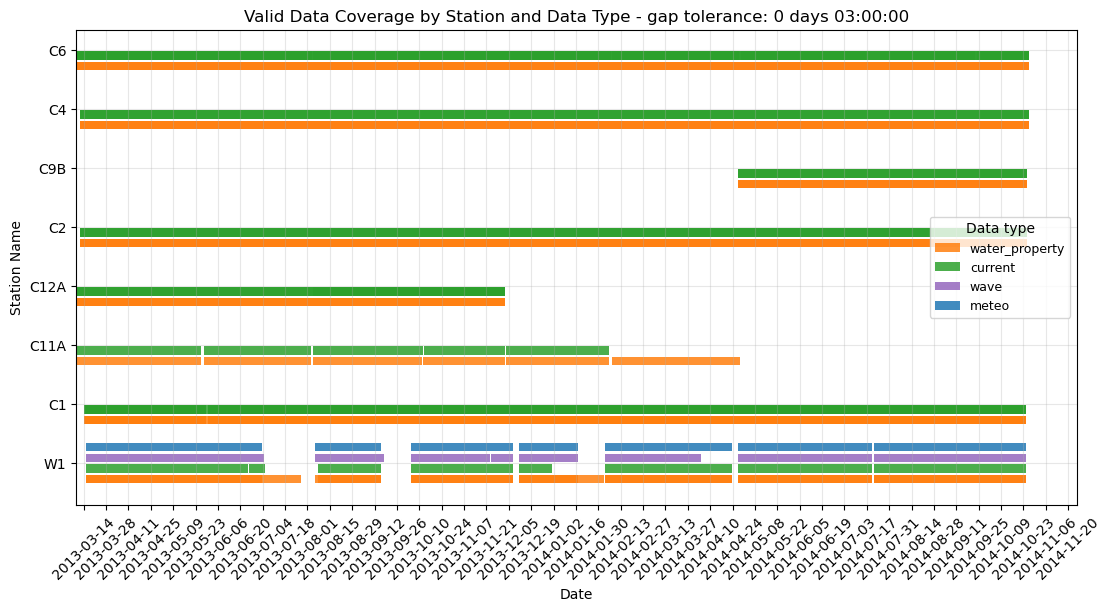

In [13]:
fig

                              <------------------ End of Document ------------------>